In [1]:
#!pip install python-docx

In [2]:
import docx

# Load the file
doc = docx.Document('Logistic Regression.docx')

# Print all paragraph text line by line
for paragraph in doc.paragraphs:
    if paragraph.text.strip():  # Skip empty lines
        print(paragraph.text)

Logistic Regression
1. Data Exploration:
a. Load the dataset and perform exploratory data analysis (EDA).
b. Examine the features, their types, and summary statistics.
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.
2. Data Preprocessing:
a. Handle missing values (e.g., imputation).
b. Encode categorical variables.
3. Model Building:
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).
b. Train the model using the training data.
4. Model Evaluation:
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.
5. Interpretation:
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).
6. Deployment with S

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
#1. Data Exploration:
#a. Load the dataset and perform exploratory data analysis (EDA).

In [5]:
df=pd.read_csv('diabetes.csv')

In [6]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
# checking the data information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.shape

(768, 9)

In [10]:
# data has 768 rows & 9 columns
# even nothing found as missing values

In [11]:
#still checking missing values

In [12]:
df.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [13]:
#Summary Statistics & Data Distribution
# View basic statistics (mean, std, min, 25%, 50%, 75%, max)
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [14]:
#Identify "Zero" Values (Hidden Missing Data)

# Check how many zeros exist in critical features

In [15]:
"""In healthcare datasets like diabetes.csv, values of 0 in columns such as Glucose,
 BloodPressure, SkinThickness,
Insulin, and BMI are biologically impossible and act as missing/missing-by-zero values."""

'In healthcare datasets like diabetes.csv, values of 0 in columns such as Glucose,\n BloodPressure, SkinThickness,\nInsulin, and BMI are biologically impossible and act as missing/missing-by-zero values.'

In [16]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[zero_cols] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [17]:
#Feature Distributions (Histograms & KDE Plots)

Visualize how each continuous feature is distributed and check for skewness:

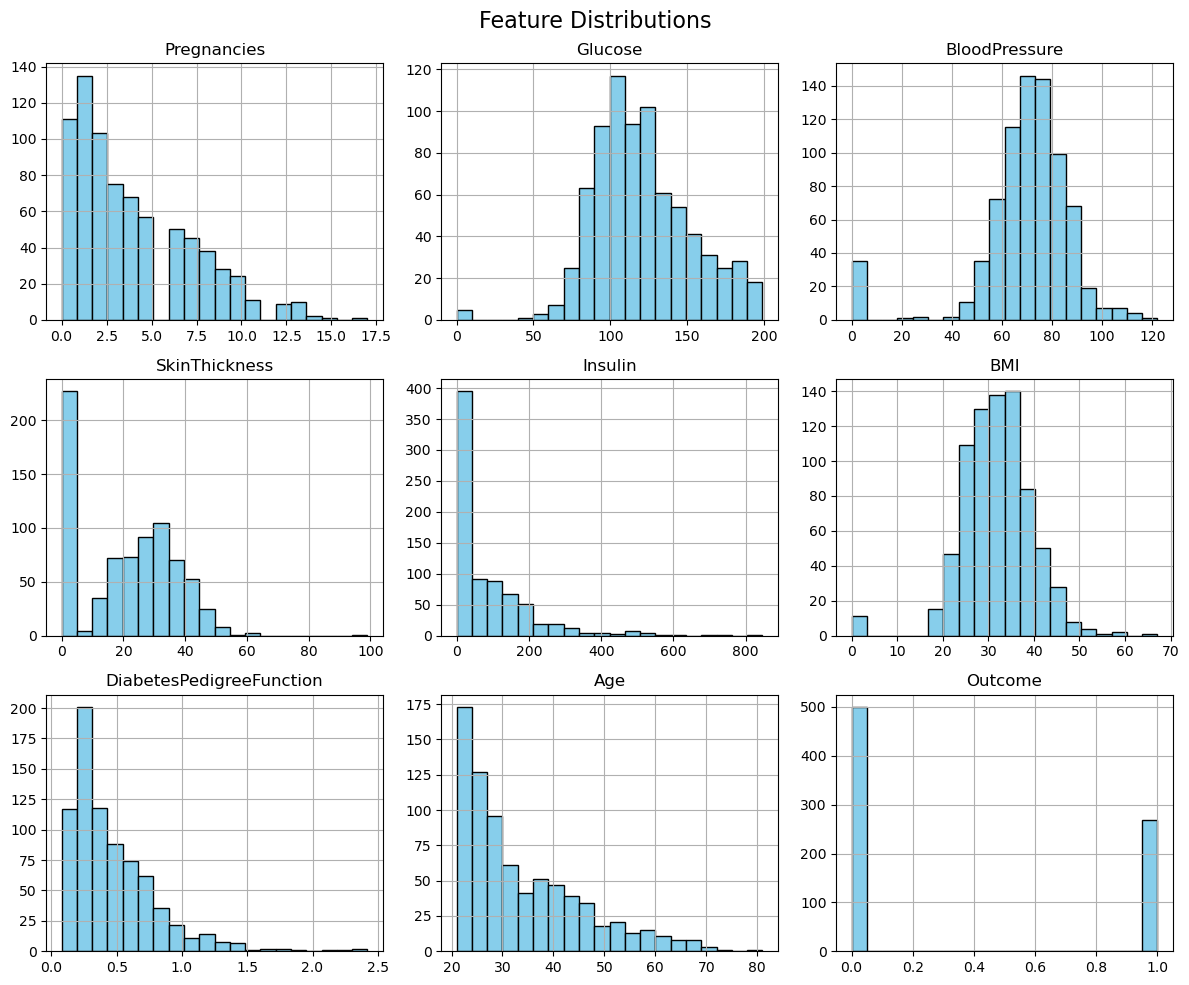

In [18]:
# Plot distribution for all features
df.hist(figsize=(12, 10), bins=20, color='skyblue', edgecolor='black')
plt.suptitle('Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

In [19]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    500
1    268
Name: count, dtype: int64


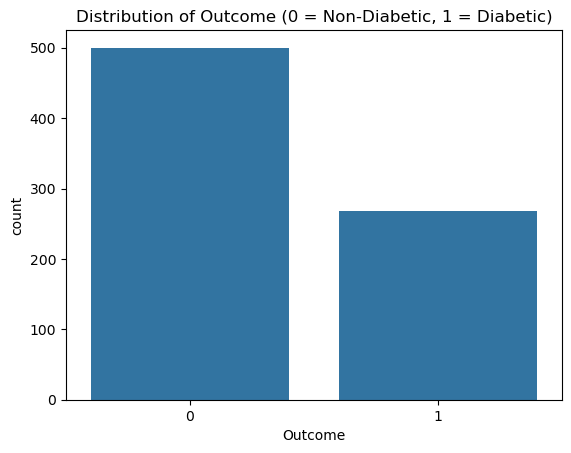

In [20]:
# Check outcome count and proportion
print(df['Outcome'].value_counts())
print("=================================")
sns.countplot(x='Outcome', data=df)
plt.title('Distribution of Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.show()

5. Outlier Detection (Boxplots)

Identify potential outliers across features:




In [21]:
# Boxplot for numerical features

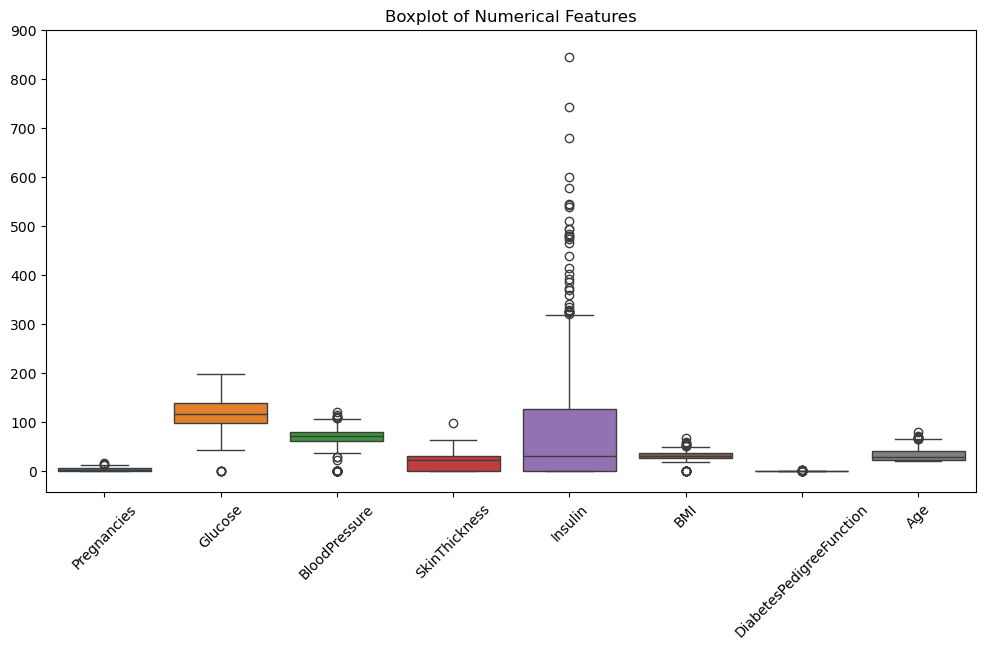

In [22]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df.drop(columns=["Outcome"]))
plt.xticks(rotation=45)
plt.yticks(np.arange(0, 901, 100))
plt.title('Boxplot of Numerical Features')
plt.show()

In [23]:
#Feature Breakdown by Outcome Group
#Compare how feature values differ between diabetic and non-diabetic individuals:

In [24]:
# Compare mean values grouped by Outcome
df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


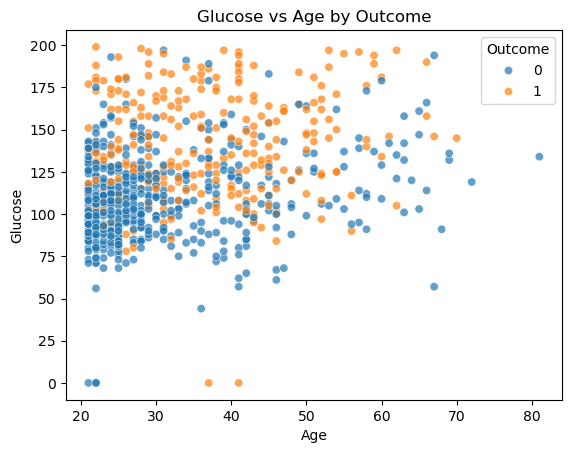

In [25]:
# Visualize Glucose vs Age colored by Outcome
sns.scatterplot(x='Age', y='Glucose', hue='Outcome', data=df, alpha=0.7)
plt.title('Glucose vs Age by Outcome')
plt.show()

In [26]:
for paragraph in doc.paragraphs:
    if paragraph.text.strip():  # Skip empty lines
        print(paragraph.text)

Logistic Regression
1. Data Exploration:
a. Load the dataset and perform exploratory data analysis (EDA).
b. Examine the features, their types, and summary statistics.
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.
2. Data Preprocessing:
a. Handle missing values (e.g., imputation).
b. Encode categorical variables.
3. Model Building:
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).
b. Train the model using the training data.
4. Model Evaluation:
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.
5. Interpretation:
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).
6. Deployment with S

In [27]:
#Model Building:
#Build a logistic regression model using appropriate libraries (e.g., scikit-learn).

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [29]:
# 1. Replace invalid 0 values with NaN in continuous features
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)

In [30]:
# 2. Separate features and target
X = df.drop(columns=['Outcome'])
y = df['Outcome']

In [31]:
# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Impute missing values using Median
imputer = SimpleImputer(strategy='median')

In [32]:
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [33]:
# 5. Feature Scaling (essential for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [34]:
#Step 2: Model Building & Training

In [35]:
# Build and train the Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

print("Model training complete!")

Model training complete!


In [36]:
for paragraph in doc.paragraphs:
    if paragraph.text.strip():  # Skip empty lines
        print(paragraph.text)

Logistic Regression
1. Data Exploration:
a. Load the dataset and perform exploratory data analysis (EDA).
b. Examine the features, their types, and summary statistics.
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.
2. Data Preprocessing:
a. Handle missing values (e.g., imputation).
b. Encode categorical variables.
3. Model Building:
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).
b. Train the model using the training data.
4. Model Evaluation:
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.
5. Interpretation:
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).
6. Deployment with S

In [37]:
#4. Model Evaluation:
#a. Evaluate the performance of the model on the testing data using
#accuracy, precision, recall, F1-score, and ROC-AUC score.
#Visualize the ROC curve.

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [39]:
# 1. Generate predictions and probability scores
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

In [40]:
# 2. Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

In [41]:
# Print Metrics Summary
print("--- Model Performance Metrics ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

--- Model Performance Metrics ---
Accuracy:  0.7078
Precision: 0.6000
Recall:    0.5000
F1-Score:  0.5455
ROC-AUC:   0.8130


In [42]:
from sklearn.metrics import classification_report, confusion_matrix


--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



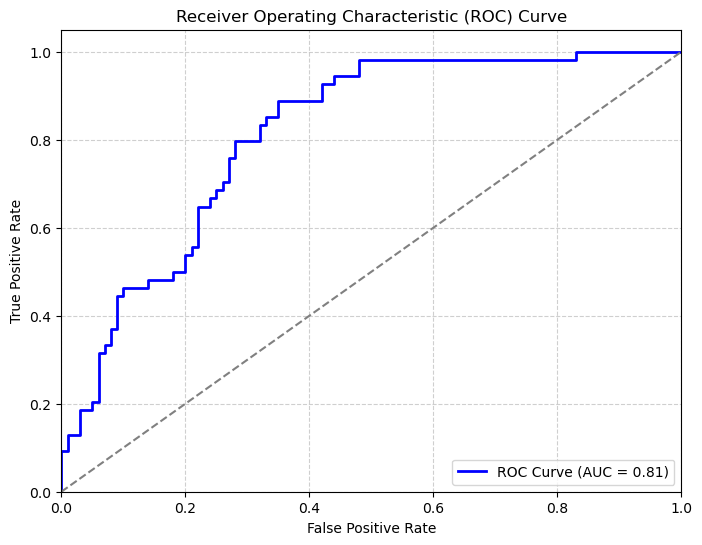

In [43]:
# Optional: Print Full Classification Report & Confusion Matrix
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred))

# 3. Visualize the ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Random guess baseline
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Key Components Handled:
Metrics Computed: Accuracy, Precision, Recall, F1-Score, and ROC-AUC score.

ROC Curve Plot: Plots the True Positive Rate vs False Positive Rate with a diagonal baseline representing random chance.

In [44]:
# 5. Interpretation:
# a. Interpret the coefficients of the logistic regression model.
# b. Discuss the significance of features in predicting the target variable (survival probability in this case).


In [45]:
#Python Code (Extracting & Visualizing Coefficients)

--- Model Coefficients & Odds Ratios ---
                 Feature  Coefficient (Log-Odds)  Odds Ratio
                 Glucose                1.182567    3.262739
                     BMI                0.688652    1.991030
             Pregnancies                0.377446    1.458554
DiabetesPedigreeFunction                0.233337    1.262807
                     Age                0.147794    1.159274
           SkinThickness                0.028321    1.028725
           BloodPressure               -0.044111    0.956848
                 Insulin               -0.066119    0.936019


C:\Users\surya\AppData\Local\Temp\ipykernel_2516\2381300312.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient (Log-Odds)', y='Feature', data=coefficients_df, palette='viridis')


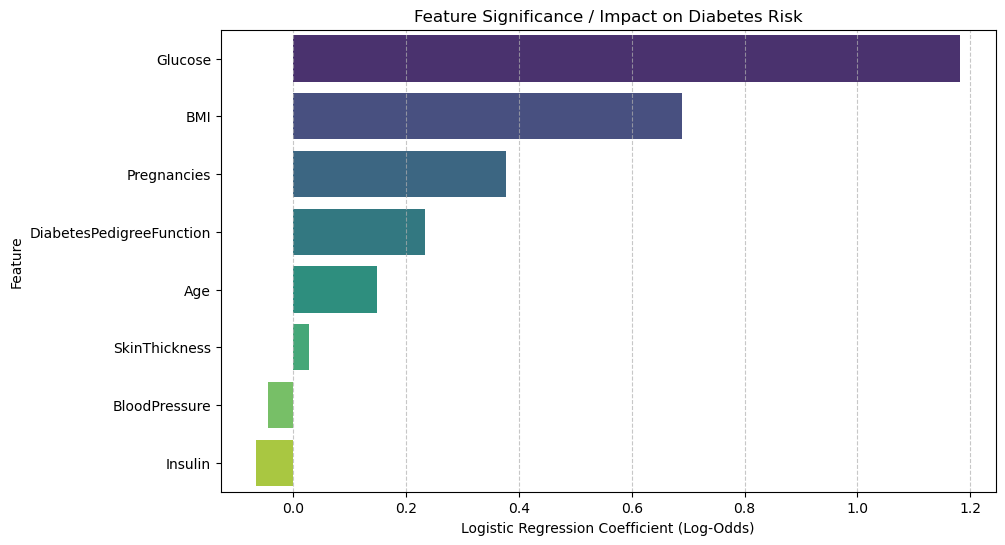

In [46]:
# Create a DataFrame for feature coefficients
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (Log-Odds)': model.coef_[0],
    'Odds Ratio': np.exp(model.coef_[0])
}).sort_values(by='Coefficient (Log-Odds)', ascending=False)

print("--- Model Coefficients & Odds Ratios ---")
print(coefficients_df.to_string(index=False))

# Plot feature importance based on coefficients
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient (Log-Odds)', y='Feature', data=coefficients_df, palette='viridis')
plt.title('Feature Significance / Impact on Diabetes Risk')
plt.xlabel('Logistic Regression Coefficient (Log-Odds)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


Interpretation & Explanation1. How to Read the CoefficientsPositive Coefficients / Odds Ratio > 1: As the scaled feature increases, the likelihood/odds of a positive outcome (diabetic outcome = 1) increases.Negative Coefficients / Odds Ratio < 1: As the feature increases, the likelihood of a positive outcome decreases.Odds Ratio ($\exp(\beta)$): Represents the multiplicative change in the odds of having diabetes for every 1 standard deviation increase in that feature.2. Feature Significance AnalysisPrimary Predictors (Highest Positive Impact):Glucose: Typically the most dominant predictor in this dataset. Higher blood glucose levels drastically increase the log-odds of being diagnosed with diabetes.BMI: High Body Mass Index significantly increases diabetes risk, reflecting the strong clinical connection between body mass and insulin resistance.Age & DiabetesPedigreeFunction: Older age and a family history of diabetes (pedigree function) also contribute positively to predicting diabetes risk.Lower Impact / Confounding Predictors:Features like SkinThickness and BloodPressure generally exhibit smaller coefficients, meaning they have a lower direct impact on the model's predictions when controlled for Glucose and BMI. (Note: The problem text mentions "survival probability" as a generic template reference, but in the context of diabetes.csv, the target variable represents diabetes diagnosis).


# Interview Questions:


# 1. What is the difference between precision and recall?
Precision (Exactness): Measures out of all instances predicted as positive, how many were actually positive
Minimizing False Positives (False Alarms) - The cost of a False Positive is high.

Recall / Sensitivity (Completeness): Measures out of all actual positive instances, how many the model correctly captured

Minimizing False Negatives (Misses) - The cost of a False Negative is high.


# 2. What is cross-validation ?
Cross-validation (CV) is a resampling technique used to evaluate how well a machine learning model generalizes to unseen data. Instead of relying on a single train-test split, cross-validation divides the dataset into multiple subsets (folds) to train and test the model iteratively.
# Why It Is Important in Binary Classification?
Prevents Overfitting & Data Leakage:A single train-test split can lead to high variance—the model might perform exceptionally well or poorly simply due to a lucky or unlucky split. Cross-validation ensures every data point is used for both training and testing.Handles Class Imbalance (Stratified K-Fold):Binary classification problems often suffer from class imbalance (e.g., 90% negative, 10% positive instances like fraud detection or medical diagnosis).Standard splits might accidentally leave out minority class samples in the test set. Stratified Cross-Validation preserves the target class proportion across every fold, giving a realistic evaluation.More Reliable Metric Estimates:In binary classification, relying on a single metric (like Accuracy) from one test split can be misleading. CV provides a mean performance score alongside a standard deviation, showing how stable metrics like ROC-AUC, Precision, Recall, and F1-Score are across different subsets.Optimal Hyperparameter Tuning:When tuning decision thresholds or model parameters (e.g., regularization terms in Logistic Regression), cross-validation ensures that chosen parameters generalize well to unseen data rather than overfitting the validation set.

In [48]:
X_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,1,90.0,62.0,12.0,43.0,27.2,0.580,24
711,5,126.0,78.0,27.0,22.0,29.6,0.439,40
373,2,105.0,58.0,40.0,94.0,34.9,0.225,25
46,1,146.0,56.0,NaN,NaN,29.7,0.564,29
682,0,95.0,64.0,39.0,105.0,44.6,0.366,22
...,...,...,...,...,...,...,...,...
451,2,134.0,70.0,NaN,NaN,28.9,0.542,23
113,4,76.0,62.0,NaN,NaN,34.0,0.391,25
556,1,97.0,70.0,40.0,NaN,38.1,0.218,30
667,10,111.0,70.0,27.0,NaN,27.5,0.141,40


In [49]:
X_test

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40
672,10,68.0,106.0,23.0,49.0,35.5,0.285,47
700,2,122.0,76.0,27.0,200.0,35.9,0.483,26
630,7,114.0,64.0,NaN,NaN,27.4,0.732,34
81,2,74.0,NaN,NaN,NaN,NaN,0.102,22
...,...,...,...,...,...,...,...,...
32,3,88.0,58.0,11.0,54.0,24.8,0.267,22
637,2,94.0,76.0,18.0,66.0,31.6,0.649,23
593,2,82.0,52.0,22.0,115.0,28.5,1.699,25
425,4,184.0,78.0,39.0,277.0,37.0,0.264,31


In [50]:
y_train

353    0
711    0
373    0
46     0
682    0
      ..
451    1
113    0
556    0
667    1
107    0
Name: Outcome, Length: 614, dtype: int64

In [51]:
y_test

44     0
672    0
700    0
630    1
81     0
      ..
32     0
637    0
593    0
425    1
273    0
Name: Outcome, Length: 154, dtype: int64

In [52]:
pd.concat([X_train, y_train], axis=1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
353,1,90.0,62.0,12.0,43.0,27.2,0.580,24,0
711,5,126.0,78.0,27.0,22.0,29.6,0.439,40,0
373,2,105.0,58.0,40.0,94.0,34.9,0.225,25,0
46,1,146.0,56.0,NaN,NaN,29.7,0.564,29,0
682,0,95.0,64.0,39.0,105.0,44.6,0.366,22,0
...,...,...,...,...,...,...,...,...,...
451,2,134.0,70.0,NaN,NaN,28.9,0.542,23,1
113,4,76.0,62.0,NaN,NaN,34.0,0.391,25,0
556,1,97.0,70.0,40.0,NaN,38.1,0.218,30,0
667,10,111.0,70.0,27.0,NaN,27.5,0.141,40,1
